In [1]:
#Load the results from GitHub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = (
    "https://raw.githubusercontent.com/"
    "tran04012006/4_STAT3013_R11"
)

OUTPUT_DIR = Path("comparison_figures")
OUTPUT_DIR.mkdir(exist_ok=True)

PHASES = [
    "pre_1_3", "during", "post_1_3",
    "post_4_7", "other"
]

MODELS = [
    "DLinear", "NLinear-X", "XGBoost",
    "LightGBM", "LSTM"
]

# Choose one variant per model where available
NLINEAR_VARIANT = "NLinear-X (KM + lich tuong lai)"
LIGHTGBM_VARIANT = "B_full_future"

def read_repo_csv(branch, path):
    url = f"{BASE}/{branch}/{path}"
    print("Reading:", url)
    return pd.read_csv(url)

# NLinear
N_BASE = "NLinear_Tien/outputs/metrics"

n_overall = read_repo_csv(
    "nlinear_forecasting", f"{N_BASE}/overall.csv"
)
n_category = read_repo_csv(
    "nlinear_forecasting", f"{N_BASE}/by_category.csv"
)
n_phase = read_repo_csv(
    "nlinear_forecasting", f"{N_BASE}/by_phase.csv"
)

# LightGBM
L_BASE = "1_model/tables"

l_overall = read_repo_csv(
    "Hoang_LightGBM_GridSearch",
    f"{L_BASE}/metrics_overall.csv"
)
l_category = read_repo_csv(
    "Hoang_LightGBM_GridSearch",
    f"{L_BASE}/overall_by_category.csv"
)
l_phase = read_repo_csv(
    "Hoang_LightGBM_GridSearch",
    f"{L_BASE}/metrics_by_segment.csv"
)

# LSTM
S_BASE = "output/lstm"

s_overall = read_repo_csv(
    "LSTM_GridSearch",
    f"{S_BASE}/metrics_test_overall.csv"
)
s_category = read_repo_csv(
    "LSTM_GridSearch",
    f"{S_BASE}/metrics_test_by_category.csv"
)
s_phase = read_repo_csv(
    "LSTM_GridSearch",
    f"{S_BASE}/metrics_test_by_phase.csv"
)

XGBOOST_EXPERIMENT = "tweedie1.2_rs02"

xgb_metrics = read_repo_csv(
    "XGBoost",
    "xgboost/outputs/breakdown_metrics.csv",
)
xgb_test = xgb_metrics.loc[
    xgb_metrics["split"].eq("test")
    & xgb_metrics["experiment"].eq(XGBOOST_EXPERIMENT)
].copy()

print("All available metric CSVs loaded.")


Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/nlinear_forecasting/NLinear_Tien/outputs/metrics/overall.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/nlinear_forecasting/NLinear_Tien/outputs/metrics/by_category.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/nlinear_forecasting/NLinear_Tien/outputs/metrics/by_phase.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/Hoang_LightGBM_GridSearch/1_model/tables/metrics_overall.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/Hoang_LightGBM_GridSearch/1_model/tables/overall_by_category.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/Hoang_LightGBM_GridSearch/1_model/tables/metrics_by_segment.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/LSTM_GridSearch/output/lstm/metrics_test_overall.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/L

In [2]:
# Create standardized comparison tables

def pct(value):
    """Convert a WAPE ratio to a percentage."""
    return float(value) * 100


def result(model, mae, rmse, wape, source, n):
    return {
        "Model": model,
        "MAE": float(mae),
        "RMSE": float(rmse),
        "WAPE": float(wape),
        "N": int(n),
        "Source": source,
    }


DLINEAR_SOURCE = "DLinear tuned weekly evaluation"
XGBOOST_SOURCE = f"GitHub test CSV ({XGBOOST_EXPERIMENT})"
GITHUB_SOURCE = "GitHub test CSV"


# 1. Overall metrics

rows = [
    result(
        "DLinear",
        2.708046,
        11.815063,
        60.519724,
        DLINEAR_SOURCE,
        177713,
    )
]

r = n_overall.loc[n_overall["model"].eq(NLINEAR_VARIANT)].iloc[0]
rows.append(result(
    "NLinear-X", r["MAE"], r["RMSE"], pct(r["WAPE"]),
    GITHUB_SOURCE, r["n"],
))

r = xgb_test.loc[
    xgb_test["by"].eq("overall") & xgb_test["group"].eq("all")
].iloc[0]
rows.append(result(
    "XGBoost", r["MAE"], r["RMSE"], pct(r["WAPE"]),
    XGBOOST_SOURCE, r["n"],
))

r = l_overall.loc[
    l_overall["split"].eq("test")
    & l_overall["model"].eq(LIGHTGBM_VARIANT)
].iloc[0]
rows.append(result(
    "LightGBM", r["MAE"], r["RMSE"], pct(r["WAPE"]),
    GITHUB_SOURCE, r["n"],
))

r = s_overall.iloc[0]
rows.append(result(
    "LSTM", r["lstm_MAE"], r["lstm_RMSE"], pct(r["lstm_WAPE"]),
    GITHUB_SOURCE, r["n"],
))

overall = pd.DataFrame(rows).set_index("Model").reindex(MODELS)


# 2. WAPE by product category

category_rows = []


def add_category(model, category_name, wape, source):
    category_rows.append({
        "Model": model,
        "Category": category_name,
        "WAPE": float(wape),
        "Source": source,
    })


for category_name, wape in [
    ("food", 56.291088),
    ("household", 92.078558),
]:
    add_category("DLinear", category_name, wape, DLINEAR_SOURCE)

for _, r in n_category.loc[n_category["model"].eq(NLINEAR_VARIANT)].iterrows():
    add_category("NLinear-X", r["category"], pct(r["WAPE"]), GITHUB_SOURCE)

for _, r in xgb_test.loc[xgb_test["by"].eq("category")].iterrows():
    add_category("XGBoost", r["group"], pct(r["WAPE"]), XGBOOST_SOURCE)

for _, r in l_category.loc[l_category["model"].eq(LIGHTGBM_VARIANT)].iterrows():
    add_category("LightGBM", r["category"], pct(r["test_WAPE"]), GITHUB_SOURCE)

for _, r in s_category.iterrows():
    add_category("LSTM", r["category"], pct(r["lstm_WAPE"]), GITHUB_SOURCE)

category = pd.DataFrame(category_rows)


# 3. MAE and WAPE by promotion phase

phase_rows = []


def add_phase(model, phase_name, mae, wape, source):
    phase_rows.append({
        "Model": model,
        "Phase": phase_name,
        "MAE": float(mae),
        "WAPE": float(wape),
        "Source": source,
    })


dlinear_by_phase = [
    ("pre_1_3", 1.830955, 72.768286),
    ("during", 2.884649, 57.051794),
    ("post_1_3", 3.416232, 72.472006),
    ("post_4_7", 2.897677, 73.766532),
    ("other", 2.674280, 59.956335),
]

for phase_name, mae, wape in dlinear_by_phase:
    add_phase("DLinear", phase_name, mae, wape, DLINEAR_SOURCE)

for _, r in n_phase.loc[n_phase["model"].eq(NLINEAR_VARIANT)].iterrows():
    add_phase(
        "NLinear-X", r["phase"], r["MAE"], pct(r["WAPE"]), GITHUB_SOURCE
    )

for _, r in xgb_test.loc[xgb_test["by"].eq("phase")].iterrows():
    add_phase("XGBoost", r["group"], r["MAE"], pct(r["WAPE"]), XGBOOST_SOURCE)

lightgbm_phase = l_phase.loc[
    l_phase["segment"].eq("phase")
    & l_phase["model"].eq(LIGHTGBM_VARIANT)
]
for _, r in lightgbm_phase.iterrows():
    add_phase("LightGBM", r["value"], r["MAE"], pct(r["WAPE"]), GITHUB_SOURCE)

for _, r in s_phase.iterrows():
    add_phase(
        "LSTM", r["phase"], r["lstm_MAE"], pct(r["lstm_WAPE"]), GITHUB_SOURCE
    )

phase = pd.DataFrame(phase_rows)


# 4. Display the comparison tables

print("OVERALL METRICS")
display(overall.round(3))

print("CATEGORY METRICS — WAPE (%)")
display(
    category.pivot(index="Model", columns="Category", values="WAPE")
    .reindex(MODELS)
    .round(2)
)

print("PROMOTION PHASE METRICS")
display(phase.round({"MAE": 3, "WAPE": 2}))

OVERALL METRICS


,MAE,RMSE,WAPE,N,Source
Model,,,,,
DLinear,2.708,11.815,60.520,177713,DLinear tuned weekly evaluation
NLinear-X,2.524,11.781,56.410,177713,GitHub test CSV
XGBoost,2.627,12.056,58.708,177713,GitHub test CSV (tweedie1.2_rs02)
LightGBM,2.562,11.911,57.253,177713,GitHub test CSV
LSTM,2.432,12.215,54.352,177713,GitHub test CSV


CATEGORY METRICS — WAPE (%)


Category,food,household
Model,,
DLinear,56.29,92.08
NLinear-X,53.26,79.91
XGBoost,55.35,83.78
LightGBM,54.01,81.45
LSTM,51.63,74.67


PROMOTION PHASE METRICS


,Model,Phase,MAE,WAPE,Source
0,DLinear,pre_1_3,1.831,72.77,DLinear tuned weekly evaluation
1,DLinear,during,2.885,57.05,DLinear tuned weekly evaluation
2,DLinear,post_1_3,3.416,72.47,DLinear tuned weekly evaluation
3,DLinear,post_4_7,2.898,73.77,DLinear tuned weekly evaluation
4,DLinear,other,2.674,59.96,DLinear tuned weekly evaluation
5,NLinear-X,during,2.771,54.80,GitHub test CSV
6,NLinear-X,other,2.512,56.31,GitHub test CSV
7,NLinear-X,post_1_3,2.808,59.58,GitHub test CSV
8,NLinear-X,post_4_7,2.298,58.51,GitHub test CSV
9,NLinear-X,pre_1_3,1.678,66.68,GitHub test CSV


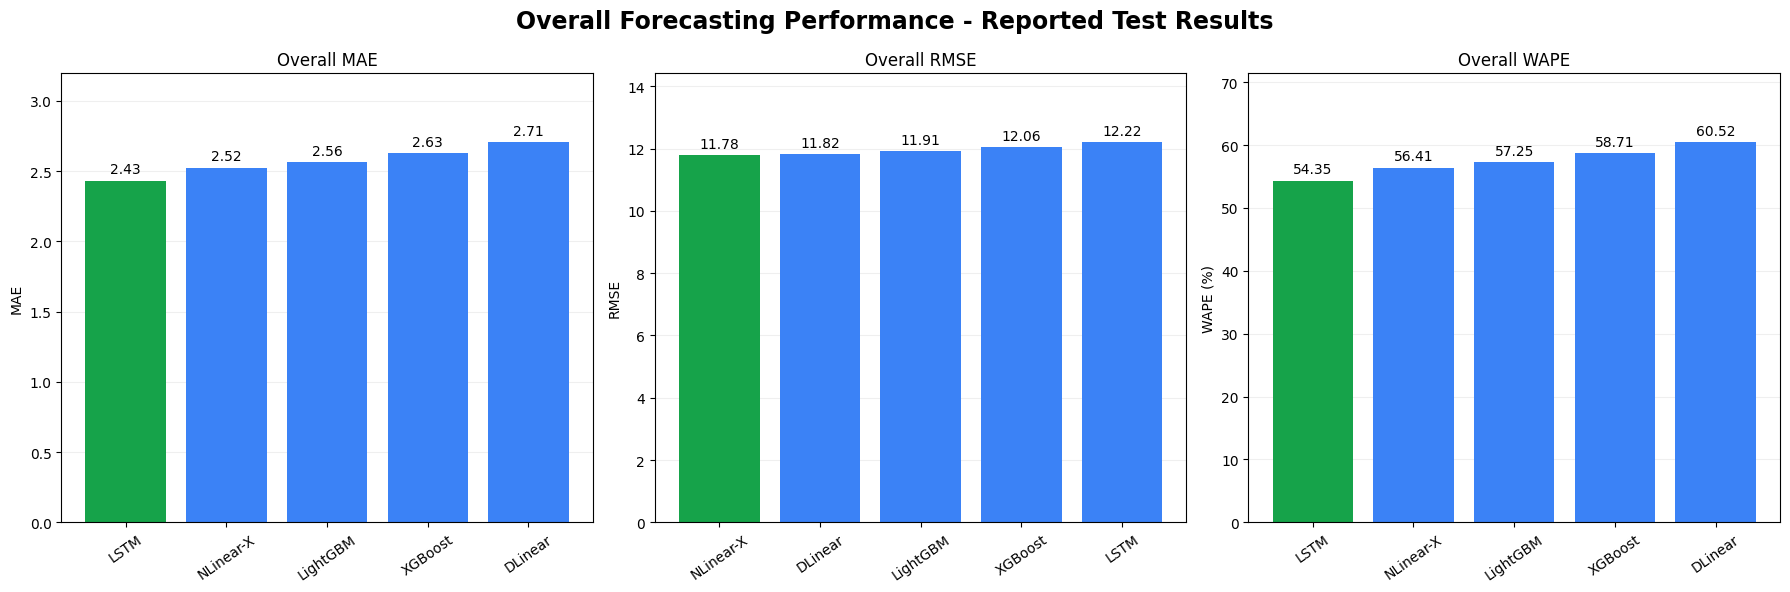

In [3]:
#Visualize overall MAE, RMSE, WAPE

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, metric in zip(
    axes, ["MAE", "RMSE", "WAPE"]
):
    values = overall[metric].sort_values()

    colors = [
        "#16A34A" if model == values.index[0]
        else "#3B82F6"
        for model in values.index
    ]

    bars = ax.bar(
        values.index, values.values,
        color=colors
    )

    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_title(f"Overall {metric}")
    ax.set_ylabel(
        metric + (" (%)" if metric == "WAPE" else "")
    )
    ax.tick_params(axis="x", rotation=35)
    ax.set_ylim(0, values.max() * 1.18)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Overall Forecasting Performance - Reported Test Results",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "01_overall_comparison.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


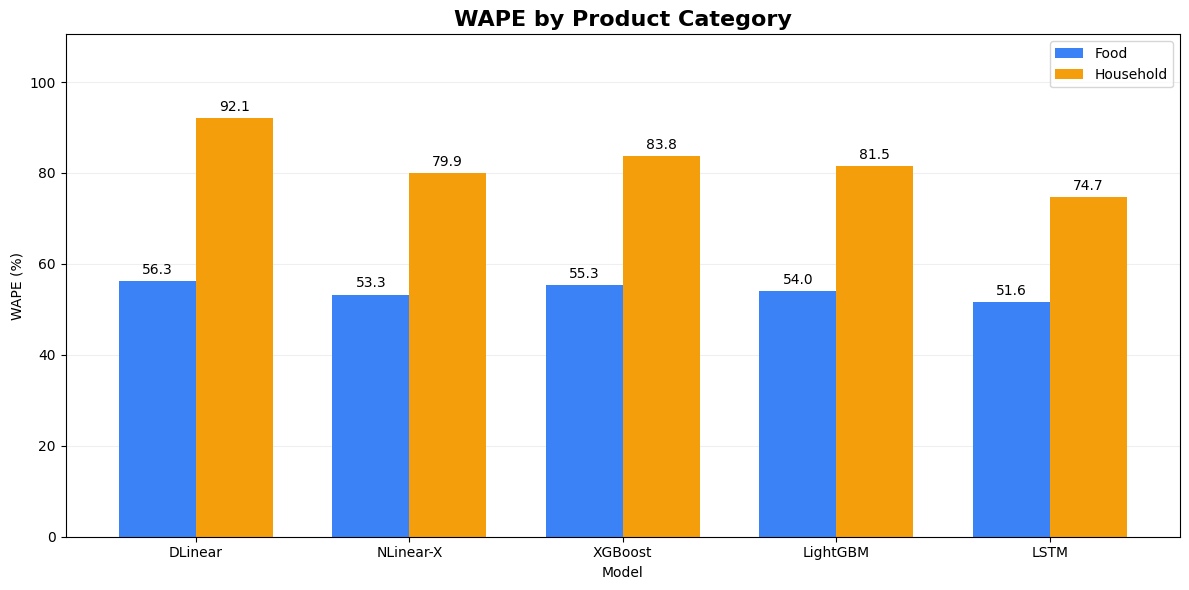

In [4]:
#Visualize Food vs Household WAPE

cat_plot = category.pivot(
    index="Model",
    columns="Category",
    values="WAPE"
).reindex(MODELS)

ax = cat_plot[["food", "household"]].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.72,
    color=["#3B82F6", "#F59E0B"]
)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", padding=3)

ax.set_title(
    "WAPE by Product Category",
    fontsize=16, fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("WAPE (%)")
ax.set_xticklabels(MODELS, rotation=0)
ax.legend(["Food", "Household"])
ax.set_ylim(0, cat_plot.max().max() * 1.2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "02_category_wape.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


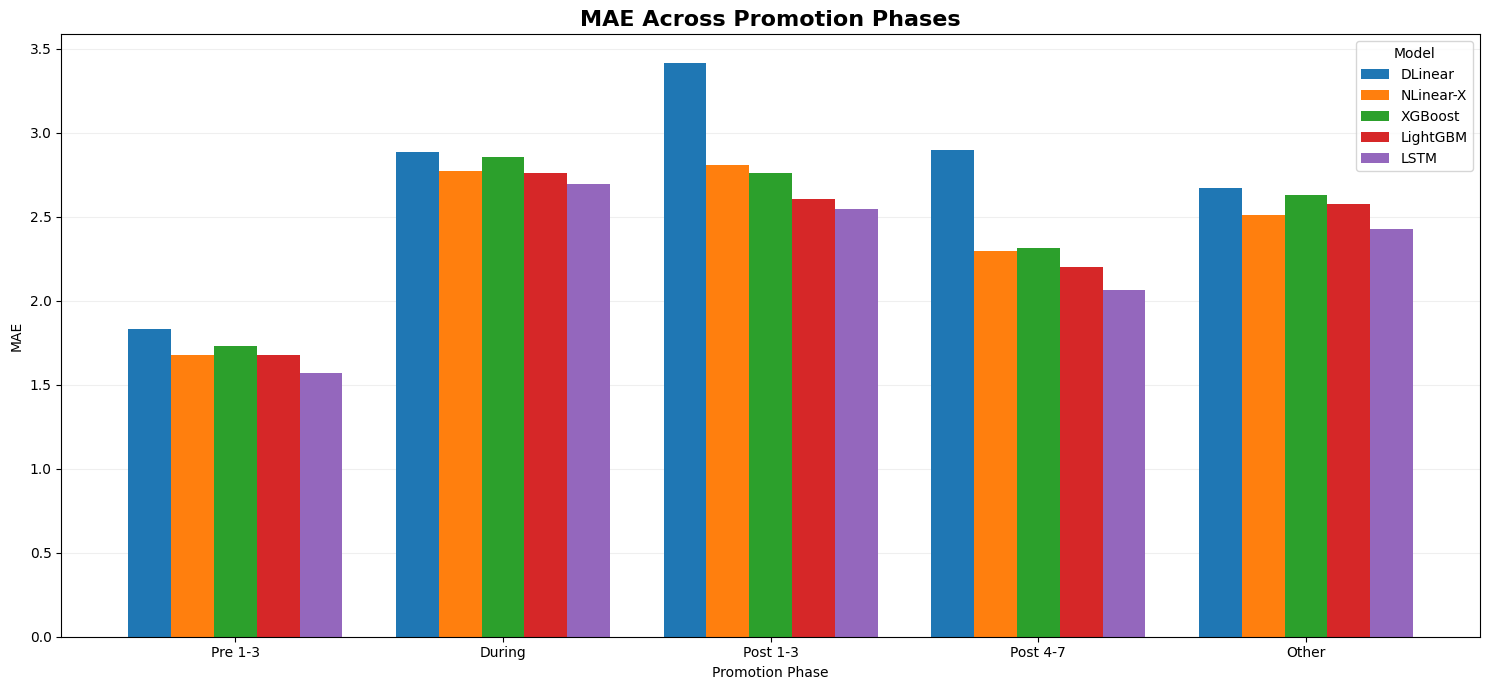

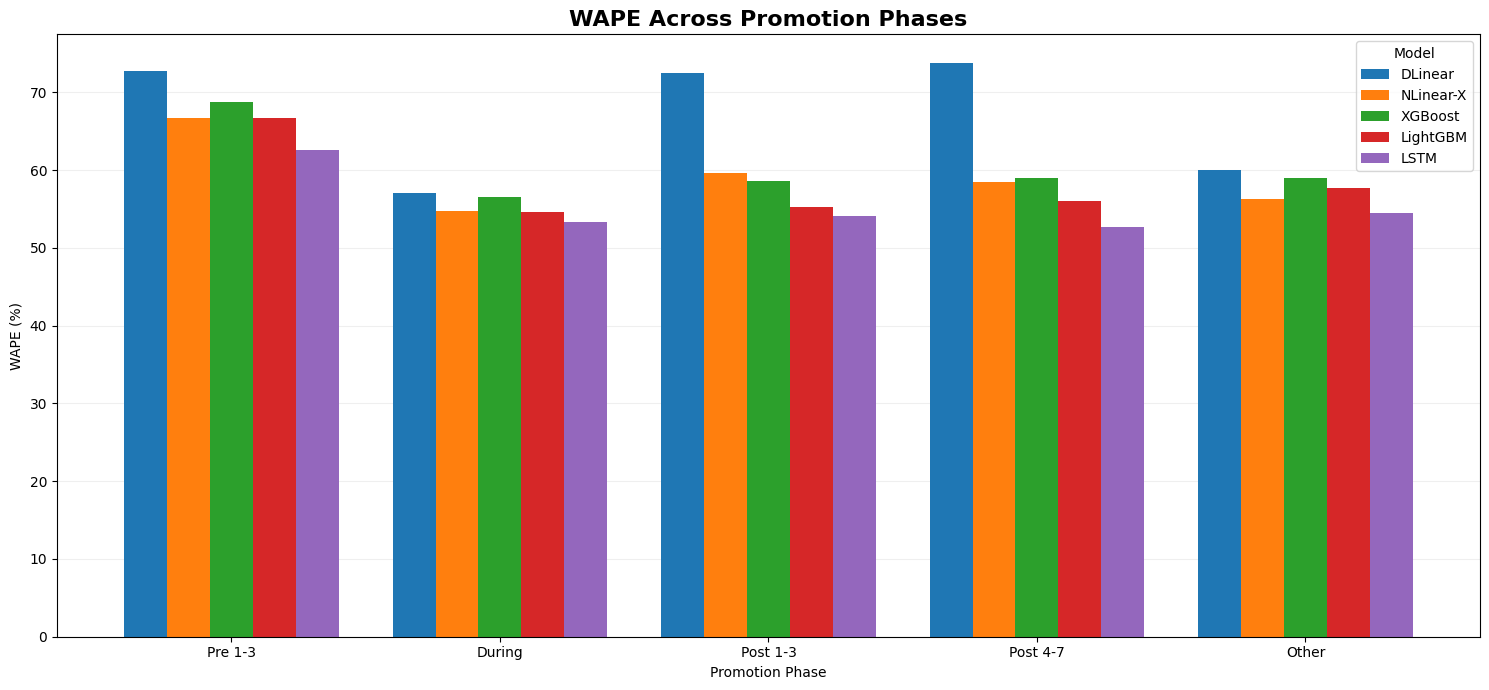

In [5]:
#Visualize MAE and WAPE across promotion phases

phase_labels = {
    "pre_1_3": "Pre 1-3",
    "during": "During",
    "post_1_3": "Post 1-3",
    "post_4_7": "Post 4-7",
    "other": "Other"
}

for metric in ["MAE", "WAPE"]:
    plot_data = phase.pivot(
        index="Phase",
        columns="Model",
        values=metric
    )

    plot_data = plot_data.reindex(
        index=PHASES,
        columns=MODELS
    )

    ax = plot_data.plot(
        kind="bar",
        figsize=(15, 7),
        width=0.8
    )

    ax.set_xticklabels(
        [phase_labels[p] for p in PHASES],
        rotation=0
    )
    ax.set_title(
        f"{metric} Across Promotion Phases",
        fontsize=16,
        fontweight="bold"
    )
    ax.set_xlabel("Promotion Phase")
    ax.set_ylabel(
        metric + (" (%)" if metric == "WAPE" else "")
    )
    ax.legend(title="Model", bbox_to_anchor=(1, 1))
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"03_phase_{metric.lower()}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()


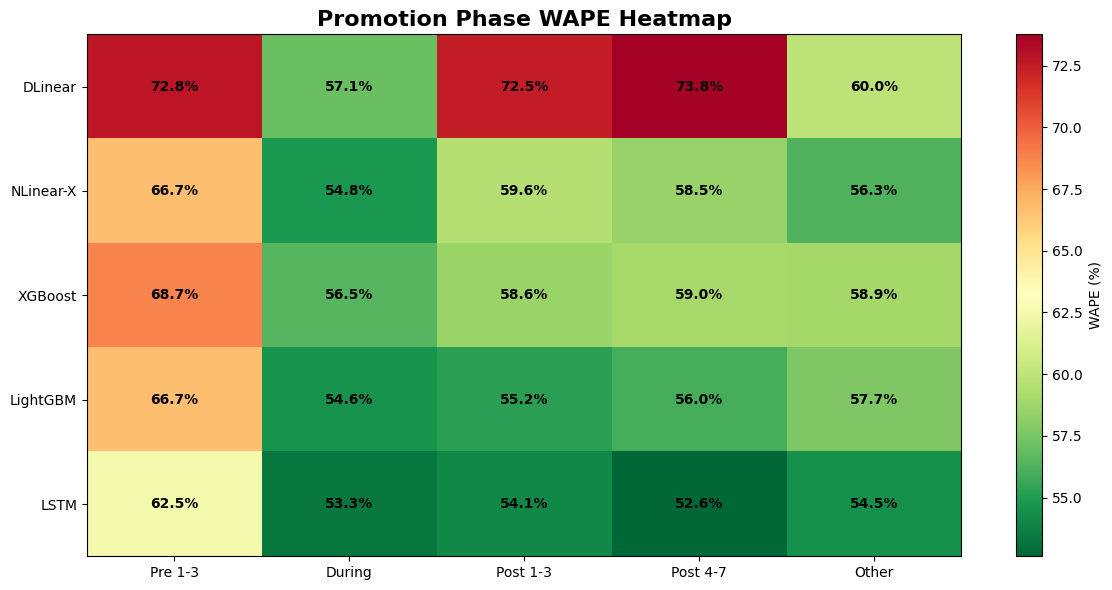

In [6]:
#Create a heatmap for promotion phases

plot_data = phase.pivot(
    index="Model",
    columns="Phase",
    values="WAPE"
).reindex(index=MODELS, columns=PHASES)

fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(
    plot_data.values,
    cmap="RdYlGn_r",
    aspect="auto"
)

ax.set_xticks(range(len(PHASES)))
ax.set_xticklabels([phase_labels[p] for p in PHASES])

ax.set_yticks(range(len(MODELS)))
ax.set_yticklabels(MODELS)

for i in range(len(MODELS)):
    for j in range(len(PHASES)):
        value = plot_data.iloc[i, j]
        if pd.notna(value):
            ax.text(
                j, i, f"{value:.1f}%",
                ha="center", va="center",
                fontweight="bold"
            )

fig.colorbar(im, ax=ax, label="WAPE (%)")

ax.set_title(
    "Promotion Phase WAPE Heatmap",
    fontsize=16, fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "04_phase_heatmap.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


In [7]:
#Automatically summarize the reported winners

def print_winner(df, metric):
    values = df[metric].dropna()
    winner = values.idxmin()
    return winner, values.min()

print("=== OVERALL ===")
for metric in ["MAE", "RMSE", "WAPE"]:
    winner, score = print_winner(overall, metric)
    print(f"{metric}: {winner} ({score:.3f})")

print("\n=== BY CATEGORY ===")
for cat in ["food", "household"]:
    subset = category[category["Category"] == cat]
    best = subset.loc[subset["WAPE"].idxmin()]
    print(
        f"{cat}: {best['Model']} "
        f"(WAPE = {best['WAPE']:.2f}%)"
    )

print("\n=== BY PROMOTION PHASE ===")
for p in PHASES:
    subset = phase[phase["Phase"] == p]

    for metric in ["MAE", "WAPE"]:
        best = subset.loc[subset[metric].idxmin()]
        print(
            f"{p} | {metric}: {best['Model']} "
            f"({best[metric]:.2f})"
        )

# Export the complete comparison tables
overall.to_csv(OUTPUT_DIR / "overall.csv")
category.to_csv(
    OUTPUT_DIR / "category.csv", index=False
)
phase.to_csv(
    OUTPUT_DIR / "phase.csv", index=False
)

print("\nAll figures and tables saved to:", OUTPUT_DIR)


=== OVERALL ===
MAE: LSTM (2.432)
RMSE: NLinear-X (11.781)
WAPE: LSTM (54.352)

=== BY CATEGORY ===
food: LSTM (WAPE = 51.63%)
household: LSTM (WAPE = 74.67%)

=== BY PROMOTION PHASE ===
pre_1_3 | MAE: LSTM (1.57)
pre_1_3 | WAPE: LSTM (62.53)
during | MAE: LSTM (2.69)
during | WAPE: LSTM (53.29)
post_1_3 | MAE: LSTM (2.55)
post_1_3 | WAPE: LSTM (54.05)
post_4_7 | MAE: LSTM (2.07)
post_4_7 | WAPE: LSTM (52.62)
other | MAE: LSTM (2.43)
other | WAPE: LSTM (54.48)

All figures and tables saved to: comparison_figures
